In [36]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import glob

Source table from NBA.API (GitHub)

From shots: TEAM_ID, TEAM_NAME, PLAYER_ID, PLAYER_NAME, GAME_DATE, GAME_ID, GAME_EVENT_ID, HOME_TEAM, AWAY_TEAM, EVENT_TYPE, SHOT_MADE, SHOT_TYPE, ACTION_TYPE,BASIC_ZONE, ZONE_NAME, ZONE_ABB, ZONE_RANGE, LOC_X, LOC_Y, SHOT_DISTANCE, QUARTER, MINS_LEFT, SECS_LEFT, SEASON, MADE

From bio: PLAYER_HEIGHT, PLAYER_HEIGHT_INCHES, PLAYER_WEIGHT, AGE, COUNTRY, COLLEGE, DRAFT_YEAR, DRAFT_ROUND, DRAFT_NUMBER

From roster: POSITION

From player_info: As a backup plan if there is missing in POSITION(roster)

Generated by code: IS_THREE, SEASON_1, SEASON_2, SECONDS_LEFT_IN_PERIOD, POSITION_GROUP

In [37]:
train = pd.read_csv("nba_project_data/processed/train_with_player_bio.csv")
print("Train shape: ", train.shape)
print(train["SEASON"].value_counts().sort_index())
for number, column in enumerate(train.columns, start=1):
  print(number, column)
train.head(10)

Train shape:  (872169, 40)
SEASON
2021-22    216722
2022-23    217220
2023-24    218700
2024-25    219527
Name: count, dtype: int64
1 SEASON_1
2 SEASON_2
3 TEAM_ID
4 TEAM_NAME
5 PLAYER_ID
6 PLAYER_NAME
7 POSITION_GROUP
8 POSITION
9 GAME_DATE
10 GAME_ID
11 GAME_EVENT_ID
12 HOME_TEAM
13 AWAY_TEAM
14 EVENT_TYPE
15 SHOT_MADE
16 ACTION_TYPE
17 SHOT_TYPE
18 BASIC_ZONE
19 ZONE_NAME
20 ZONE_ABB
21 ZONE_RANGE
22 LOC_X
23 LOC_Y
24 SHOT_DISTANCE
25 QUARTER
26 MINS_LEFT
27 SECS_LEFT
28 SEASON
29 MADE
30 SECONDS_LEFT_IN_PERIOD
31 IS_THREE
32 PLAYER_HEIGHT
33 PLAYER_HEIGHT_INCHES
34 PLAYER_WEIGHT
35 AGE
36 COUNTRY
37 COLLEGE
38 DRAFT_YEAR
39 DRAFT_ROUND
40 DRAFT_NUMBER


,SEASON_1,SEASON_2,TEAM_ID,TEAM_NAME,PLAYER_ID,PLAYER_NAME,POSITION_GROUP,POSITION,GAME_DATE,GAME_ID,...,IS_THREE,PLAYER_HEIGHT,PLAYER_HEIGHT_INCHES,PLAYER_WEIGHT,AGE,COUNTRY,COLLEGE,DRAFT_YEAR,DRAFT_ROUND,DRAFT_NUMBER
0,2022,2021-22,1610612737,Atlanta Hawks,1628381,John Collins,F,F-C,10-21-2021,22100014,...,0,6-9,81.0,226.0,24.0,USA,Wake Forest,2017.0,1.0,19.0
1,2022,2021-22,1610612737,Atlanta Hawks,1629631,De'Andre Hunter,F,F-G,10-21-2021,22100014,...,0,6-8,80.0,221.0,24.0,USA,Virginia,2019.0,1.0,4.0
2,2022,2021-22,1610612737,Atlanta Hawks,1629027,Trae Young,G,G,10-21-2021,22100014,...,0,6-1,73.0,164.0,23.0,USA,Oklahoma,2018.0,1.0,5.0
3,2022,2021-22,1610612737,Atlanta Hawks,1628381,John Collins,F,F-C,10-21-2021,22100014,...,0,6-9,81.0,226.0,24.0,USA,Wake Forest,2017.0,1.0,19.0
4,2022,2021-22,1610612737,Atlanta Hawks,203992,Bogdan Bogdanović,G,G,10-21-2021,22100014,...,1,6-6,78.0,225.0,29.0,Serbia,NaN,2014.0,1.0,27.0
5,2022,2021-22,1610612737,Atlanta Hawks,203992,Bogdan Bogdanović,G,G,10-21-2021,22100014,...,1,6-6,78.0,225.0,29.0,Serbia,NaN,2014.0,1.0,27.0
6,2022,2021-22,1610612737,Atlanta Hawks,1629027,Trae Young,G,G,10-21-2021,22100014,...,0,6-1,73.0,164.0,23.0,USA,Oklahoma,2018.0,1.0,5.0
7,2022,2021-22,1610612737,Atlanta Hawks,203991,Clint Capela,C,C,10-21-2021,22100014,...,0,6-10,82.0,256.0,28.0,Switzerland,NaN,2014.0,1.0,25.0
8,2022,2021-22,1610612737,Atlanta Hawks,1629027,Trae Young,G,G,10-21-2021,22100014,...,1,6-1,73.0,164.0,23.0,USA,Oklahoma,2018.0,1.0,5.0
9,2022,2021-22,1610612737,Atlanta Hawks,1629631,De'Andre Hunter,F,F-G,10-21-2021,22100014,...,0,6-8,80.0,221.0,24.0,USA,Virginia,2019.0,1.0,4.0


In [38]:
print(train["MADE"].value_counts())
print(train["MADE"].value_counts(normalize=True).sort_index()*100) #percentage
print("Unique target valiues: ", train["MADE"].unique())
print("Missing target values: ", train["MADE"].isna().sum())

MADE
0    462674
1    409495
Name: count, dtype: int64
MADE
0    53.048664
1    46.951336
Name: proportion, dtype: float64
Unique target valiues:  [1 0]
Missing target values:  0


Dateset structure

The training set contains 872,169 shot attempts and 40 columns. (39 feature, 1 target) 

Each ovservation represent one NBA shot attempt. 

The training set cover the 2021-22 through 2024-25 seasons, while the 2025-26 season is reserved as the final test set. 

The prediction target is "MADE", where 1 represents a made shot and 0 represents a missed shot. 

The target contains no missing or invalid values.

In [39]:
made_shot_mismatch = (train["MADE"] != train["SHOT_MADE"].astype(int)).sum()
print("MADE vs SHOT_MADE mismatches: " ,made_shot_mismatch)
event_made = (train["EVENT_TYPE"] == "Made Shot").astype(int)
event_mismatch = (train["MADE"] != event_made).sum()
print("MADE vs EVENt_TYPE mismatches: ", event_mismatch)
target = "MADE"
redundant_columns = ["SHOT_MADE", "EVENT_TYPE"]
#compare to feature "MADE", "SHOT_MADE", "EVENT_TYPE", they are redundant, so we just use "MADE" when we make a model

MADE vs SHOT_MADE mismatches:  0
MADE vs EVENt_TYPE mismatches:  0


In [40]:
season_mismatch = (train["SEASON_2"] != train["SEASON"]).sum()
print("SEASON_2 vs SEASON mismatches: ", season_mismatch)
calculated_season_1 = (train["SEASON"].str[-2:].astype(int)+2000)
season_1_mismatch = (train["SEASON_1"] != calculated_season_1).sum()
print("SEASON_1 vs SEASON mismatches: ", season_1_mismatch)
if "SEASON_1" not in redundant_columns:
    redundant_columns.append("SEASON_1")
if "SEASON_2" not in redundant_columns:
    redundant_columns.append("SEASON_2")
# redundant "SEASON_1" and "SEASON_2"

SEASON_2 vs SEASON mismatches:  0
SEASON_1 vs SEASON mismatches:  0


In [41]:
calculated_seconds = (train["MINS_LEFT"]*60 + train["SECS_LEFT"])
time_mismatch = (train["SECONDS_LEFT_IN_PERIOD"] != calculated_seconds).sum()
print("Time mismatches: ", time_mismatch)
if "MINS_LEFT" not in redundant_columns:
    redundant_columns.append("MINS_LEFT")
if "SECS_LEFT" not in redundant_columns:
    redundant_columns.append("SECS_LEFT")
# "MINS_LEFT" and "SECS_LEFT" just "SECONDS_LEFT_IN_PERIOD"

Time mismatches:  0


In [42]:

calculated_height = (train["PLAYER_HEIGHT"].str[0].astype(int)*12+train["PLAYER_HEIGHT"].str[2:].astype(int))
height_mismatch = (train["PLAYER_HEIGHT_INCHES"] != calculated_height).sum()
print("Height mismatches: ", height_mismatch)
if "PLAYER_HEIGHT" not in redundant_columns:
    redundant_columns.append("PLAYER_HEIGHT")
# "PLYAER_HEIGHT" redundant


Height mismatches:  0


In [43]:
three_from_type = (train["SHOT_TYPE"]== "3PT Field Goal").astype(int)
three_mismatch = (three_from_type!= train["IS_THREE"]).sum()
print("SHOT_TYPE vs IS_THREE mismatches:",three_mismatch)
if "SHOT_TYPE" not in redundant_columns:
    redundant_columns.append("SHOT_TYPE")
# "SHOT_TYPE" redundant

SHOT_TYPE vs IS_THREE mismatches: 0


In [44]:
position_type = (train["POSITION"].str[0])
position_mismatch = (position_type != train["POSITION_GROUP"]).sum()
print("POSITION vs POSITION_GROUP mismatches: ", position_mismatch)
if "POSITION_GROUP" not in redundant_columns:
  redundant_columns.append("POSITION_GROUP")
# "POSITION_GROUP" redundant

POSITION vs POSITION_GROUP mismatches:  0


In [45]:
def create_zone_abb(zone_name):
  words = zone_name.split()
  letters = []
  for word in words:
    if word != "Side":
      first_letter = word[0]
      letters.append(first_letter)
  zone_abb = "".join(letters)
  return zone_abb

calculated_zone_abb = train["ZONE_NAME"].apply(create_zone_abb)
zone_mismatch = (calculated_zone_abb != train["ZONE_ABB"]).sum()
print("ZONE_NAME vs ZONE_ABB mismatches: ", zone_mismatch)
if "ZONE_ABB" not in redundant_columns:
  redundant_columns.append("ZONE_ABB")
# "ZONE_ABB" redundant

ZONE_NAME vs ZONE_ABB mismatches:  0


ALL the redundant data is SHOT_MADE, EVENT_TYPE, SEASON_1, SEASON_2, MINS_LEFT, SECS_LEFT, PLAYER_HEIGHT, SHOT_TYPE, ZONE_ABB, POSITION_GROUP, 

In [46]:
new_train = train.drop(columns = redundant_columns)
# dataset after remove the redundant
new_train.columns
# new_train.shape

Index(['TEAM_ID', 'TEAM_NAME', 'PLAYER_ID', 'PLAYER_NAME', 'POSITION',
       'GAME_DATE', 'GAME_ID', 'GAME_EVENT_ID', 'HOME_TEAM', 'AWAY_TEAM',
       'ACTION_TYPE', 'BASIC_ZONE', 'ZONE_NAME', 'ZONE_RANGE', 'LOC_X',
       'LOC_Y', 'SHOT_DISTANCE', 'QUARTER', 'SEASON', 'MADE',
       'SECONDS_LEFT_IN_PERIOD', 'IS_THREE', 'PLAYER_HEIGHT_INCHES',
       'PLAYER_WEIGHT', 'AGE', 'COUNTRY', 'COLLEGE', 'DRAFT_YEAR',
       'DRAFT_ROUND', 'DRAFT_NUMBER'],
      dtype='object')

In [47]:
missing_summary = pd.DataFrame({"Missing Count": train.isna().sum(),
                                "Missing Percent": train.isna().mean()*100})
print(missing_summary[missing_summary['Missing Percent'] > 0])

               Missing Count  Missing Percent
PLAYER_WEIGHT            685         0.078540
COLLEGE               113664        13.032337
DRAFT_YEAR             94696        10.857529
DRAFT_ROUND            96454        11.059095
DRAFT_NUMBER           98400        11.282217


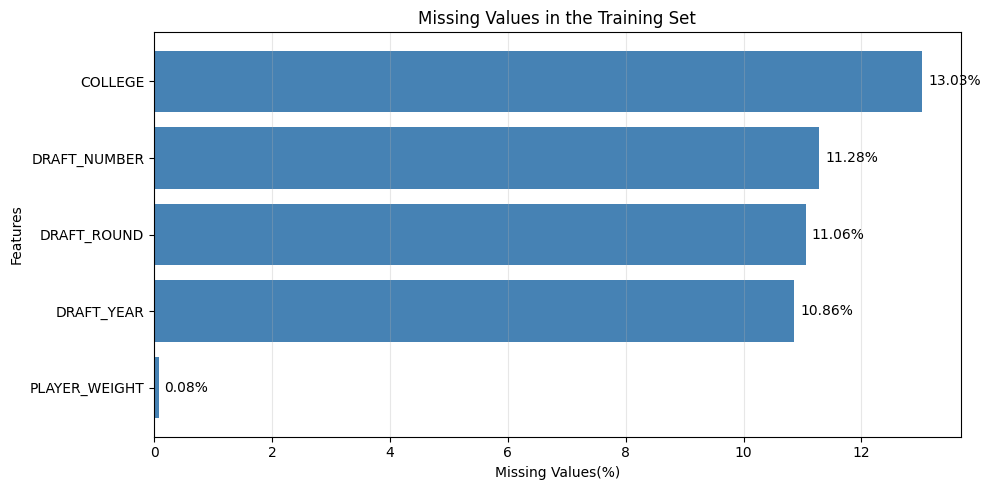

In [48]:
missing_only = missing_summary[missing_summary["Missing Percent"] > 0].sort_values("Missing Percent")
plt.figure(figsize=(10, 5))
bars = plt.barh(missing_only.index, missing_only["Missing Percent"], color="steelblue")
plt.xlabel("Missing Values(%)")
plt.ylabel("Features")
plt.title("Missing Values in the Training Set")
plt.grid(axis='x', alpha=0.3)
for bar in bars:
  width = bar.get_width()
  plt.text(
    width + 0.1,
    bar.get_y() + bar.get_height() / 2,
    f"{width:.2f}%",
    va='center'
  )
  plt.tight_layout()

In [49]:
draft_missing_check = pd.DataFrame({"DRAFT_YEAR_MISSING": train["DRAFT_YEAR"].isna(),
                                    "DRAFT_ROUND_MISSING": train["DRAFT_ROUND"].isna(),
                                    "DRAFT_NUMBER_MISSING": train["DRAFT_NUMBER"].isna()})
draft_missing_check.value_counts()
# true means missing

DRAFT_YEAR_MISSING  DRAFT_ROUND_MISSING  DRAFT_NUMBER_MISSING
False               False                False                   773769
True                True                 True                     94696
False               False                True                      1946
                    True                 True                      1758
Name: count, dtype: int64

Most missing draft values occurs together, which may indicate undrafted players or absent draft records. However, 3704 shot records have only partially missing draft information, showing that some biographical records are incomplete. These variable will not be used in the initial baseline models.

Draft variables were excluded from the initial baseline models because they describe players' entry into the NBA rather than the immediate context of a shot, and they also contain substantial missing values. They may be reconsidered in later feature-engineering experiments.

In [50]:
college_missing_players = train.loc[train['COLLEGE'].isna(),["PLAYER_ID", "PLAYER_NAME", "COUNTRY"]].drop_duplicates(subset=["PLAYER_ID"])
print(college_missing_players)
print("Number of players with missing college: ", len(college_missing_players))
# use drop_duplicates because one player maybe shot multiple times.
weight_missing_players = train.loc[train['PLAYER_WEIGHT'].isna(), ["PLAYER_ID", "PLAYER_NAME", "SEASON"]].drop_duplicates(subset=["PLAYER_ID", "SEASON"])
print(weight_missing_players)
print("Number of player with missing weight: ", len(weight_missing_players))


        PLAYER_ID              PLAYER_NAME      COUNTRY
4          203992        Bogdan Bogdanović       Serbia
7          203991             Clint Capela  Switzerland
87        1627789  Timothe Luwawu-Cabarrot       France
210        101150             Lou Williams          USA
304        201568         Danilo Gallinari        Italy
...           ...                      ...          ...
843137    1642530            Yuki Kawamura        Japan
850127    1642259                Alex Sarr       France
857524    1641842        Ronald Holland II          USA
861596    1641752            Bobi Klintman       Sweden
864878    1642275           Tidjane Salaün       France

[118 rows x 3 columns]
Number of players with missing college:  118
        PLAYER_ID   PLAYER_NAME   SEASON
842480    1642377  Jaylen Wells  2024-25
864613    1642449    Tolu Smith  2024-25
Number of player with missing weight:  2


In [51]:
# since the missing data from same player and same season
# I found their weight in the offical website
# Source: https://www.nba.com/summer-league/2024/vegas/team/1610612763/grizzlies
# Jaylen Wells is 206 lbs and Tolu Smith is 245 lbs

official_weight = {1642377: 206, 1642449: 245}
new_train["PLAYER_WEIGHT"] = (new_train["PLAYER_WEIGHT"].fillna(new_train["PLAYER_ID"].map(official_weight)))
print(new_train["PLAYER_WEIGHT"].isna().sum())

0


In [52]:
college_missing_players = (train.loc[train["COLLEGE"].isna(),["PLAYER_ID", "PLAYER_NAME", "COUNTRY"]].drop_duplicates(subset=["PLAYER_ID"]))
print(college_missing_players)

        PLAYER_ID              PLAYER_NAME      COUNTRY
4          203992        Bogdan Bogdanović       Serbia
7          203991             Clint Capela  Switzerland
87        1627789  Timothe Luwawu-Cabarrot       France
210        101150             Lou Williams          USA
304        201568         Danilo Gallinari        Italy
...           ...                      ...          ...
843137    1642530            Yuki Kawamura        Japan
850127    1642259                Alex Sarr       France
857524    1641842        Ronald Holland II          USA
861596    1641752            Bobi Klintman       Sweden
864878    1642275           Tidjane Salaün       France

[118 rows x 3 columns]


In [53]:
player_school_list = []
for file_path in glob.glob("nba_project_data/raw/player_info/player_*.csv"):
    player_info = pd.read_csv(file_path)

    if len(player_info) > 0:
        player_id = player_info.loc[0, "PERSON_ID"]
        school = player_info.loc[0, "SCHOOL"]

        player_school_list.append({"PLAYER_ID": player_id,"SCHOOL": school})

player_school = pd.DataFrame(player_school_list)

college_check = college_missing_players.merge(player_school,on="PLAYER_ID",how="left")

college_check["SCHOOL_AVAILABLE"] = (college_check["SCHOOL"].fillna("").str.strip().ne(""))
display(college_check)
print(college_check["SCHOOL_AVAILABLE"].value_counts())

,PLAYER_ID,PLAYER_NAME,COUNTRY,SCHOOL,SCHOOL_AVAILABLE
0,203992,Bogdan Bogdanović,Serbia,NaN,False
1,203991,Clint Capela,Switzerland,NaN,False
2,1627789,Timothe Luwawu-Cabarrot,France,NaN,False
3,101150,Lou Williams,USA,NaN,False
4,201568,Danilo Gallinari,Italy,NaN,False
...,...,...,...,...,...
113,1642530,Yuki Kawamura,Japan,NaN,False
114,1642259,Alex Sarr,France,NaN,False
115,1641842,Ronald Holland II,USA,NaN,False
116,1641752,Bobi Klintman,Sweden,Wake Forest,True


SCHOOL_AVAILABLE
False    93
True     25
Name: count, dtype: int64


Among the 118 players with missing COLLEGE, 93 also had no SCHOOL information in player_info, while 25 had a non-empty SCHOOL value.

The missing COLLEGE values were compared with the SCHOOL field from the player_info data. However, SCHOOL contains different types of institutions, including colleges, high schools, NBA development programs, and international professional teams. Therefore, it could not be used to reliably fill the missing COLLEGE values. 

In [54]:
missing_summary = pd.DataFrame({"Missing Count": new_train.isna().sum(),
                                "Missing Percent": new_train.isna().mean()*100})
print(missing_summary[missing_summary['Missing Percent'] > 0])

              Missing Count  Missing Percent
COLLEGE              113664        13.032337
DRAFT_YEAR            94696        10.857529
DRAFT_ROUND           96454        11.059095
DRAFT_NUMBER          98400        11.282217


In [55]:
new_train["COLLEGE"] = new_train["COLLEGE"].fillna("Unknown_or_No_College")
print(new_train["COLLEGE"].isna().sum())

0


Among the 118 players with missing COLLEGE, 25 had a non-empty SCHOOL value in the player_info data, while 93 had no school information in either source. However, SCHOOL contains different types of institutions, including colleges, high schools, development programs, and international professional teams. Therefore, it could not be used to reliably fill COLLEGE. The missing values were retained as a separate Unknown_or_No_College category.

In [56]:
# now look at the outlier
numeric_quality_columns = ["SHOT_DISTANCE","LOC_X","LOC_Y","QUARTER","MINS_LEFT","SECS_LEFT","SECONDS_LEFT_IN_PERIOD","PLAYER_HEIGHT_INCHES","PLAYER_WEIGHT","AGE"]
train[numeric_quality_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
SHOT_DISTANCE,872169.0,13.700462,10.600109,0.00,3.00,13.00,25.00,88.00
LOC_X,872169.0,0.213395,11.472166,-25.00,-4.50,0.00,5.00,25.00
LOC_Y,872169.0,14.822391,9.514809,0.05,6.65,10.75,23.45,93.05
QUARTER,872169.0,2.480469,1.130460,1.00,1.00,2.00,3.00,7.00
MINS_LEFT,872169.0,5.379960,3.452392,0.00,2.00,5.00,8.00,12.00
SECS_LEFT,872169.0,28.847689,17.410395,0.00,14.00,29.00,44.00,59.00
SECONDS_LEFT_IN_PERIOD,872169.0,351.645266,207.833238,0.00,171.00,353.00,532.00,720.00
PLAYER_HEIGHT_INCHES,872169.0,78.292197,3.173267,67.00,76.00,78.00,80.00,90.00
PLAYER_WEIGHT,871484.0,215.289319,23.927690,159.00,197.00,215.00,230.00,311.00
AGE,872169.0,26.613528,4.260431,19.00,23.00,26.00,29.00,43.00


In [57]:
quality_checks = {"Negative shot distance": (train["SHOT_DISTANCE"] < 0).sum(),
                  "Quarter below 1": (train["QUARTER"] < 1).sum(),
                  "Negative minutes": (train["MINS_LEFT"] < 0).sum(),
                  "Seconds below 0": (train["SECS_LEFT"] < 0).sum(),
                  "Seconds above 60": (train["SECS_LEFT"] > 59).sum(),
                  "Negative time remaining": (train["SECONDS_LEFT_IN_PERIOD"] < 0).sum(),
                  "Invalide MADE value": (~train["MADE"].isin([0,1])).sum(),
                  "LOC_X below -25": (train["LOC_X"] < -25).sum(),
                  "LOC_X above 25": (train["LOC_X"] > 25).sum(),
                  "LOC_Y below 0": (train["LOC_Y"] < 0).sum(),
                  "LOC_Y above 94": (train["LOC_Y"] > 94).sum(),
                  "Mins left >= 12": (train["MINS_LEFT"] >= 12).sum() #double check this
                  }
print(quality_checks)

{'Negative shot distance': np.int64(0), 'Quarter below 1': np.int64(0), 'Negative minutes': np.int64(0), 'Seconds below 0': np.int64(0), 'Seconds above 60': np.int64(0), 'Negative time remaining': np.int64(0), 'Invalide MADE value': np.int64(0), 'LOC_X below -25': np.int64(0), 'LOC_X above 25': np.int64(0), 'LOC_Y below 0': np.int64(0), 'LOC_Y above 94': np.int64(0), 'Mins left >= 12': np.int64(3)}


Three records contain exactly 12:00 remaining in a period. This is a valid boundary value and may represent events recorded at the start of a period. Because these records could not be confirmed as erroneous and represent only three observations, they were retained

In [58]:
correlation_columns = [
    "MADE",
    "SHOT_DISTANCE",
    "QUARTER",
    "SECONDS_LEFT_IN_PERIOD",
    "IS_THREE",
    "PLAYER_HEIGHT_INCHES",
    "PLAYER_WEIGHT",
    "AGE"
]
correlation_matrix = train[correlation_columns].corr()
correlation_matrix

,MADE,SHOT_DISTANCE,QUARTER,SECONDS_LEFT_IN_PERIOD,IS_THREE,PLAYER_HEIGHT_INCHES,PLAYER_WEIGHT,AGE
MADE,1.000000,-0.233138,-0.006862,0.016200,-0.179362,0.066093,0.064535,0.006613
SHOT_DISTANCE,-0.233138,1.000000,-0.001911,-0.028944,0.888453,-0.195253,-0.190385,0.058021
QUARTER,-0.006862,-0.001911,1.000000,-0.010979,0.005951,-0.034126,-0.033815,-0.019319
SECONDS_LEFT_IN_PERIOD,0.016200,-0.028944,-0.010979,1.000000,-0.022557,0.048575,0.037839,0.015876
IS_THREE,-0.179362,0.888453,0.005951,-0.022557,1.000000,-0.154692,-0.154865,0.032700
PLAYER_HEIGHT_INCHES,0.066093,-0.195253,-0.034126,0.048575,-0.154692,1.000000,0.736319,-0.043238
PLAYER_WEIGHT,0.064535,-0.190385,-0.033815,0.037839,-0.154865,0.736319,1.000000,0.151472
AGE,0.006613,0.058021,-0.019319,0.015876,0.032700,-0.043238,0.151472,1.000000


In [59]:
made_correlations = (correlation_matrix["MADE"].sort_values())
print(made_correlations)

SHOT_DISTANCE            -0.233138
IS_THREE                 -0.179362
QUARTER                  -0.006862
AGE                       0.006613
SECONDS_LEFT_IN_PERIOD    0.016200
PLAYER_WEIGHT             0.064535
PLAYER_HEIGHT_INCHES      0.066093
MADE                      1.000000
Name: MADE, dtype: float64


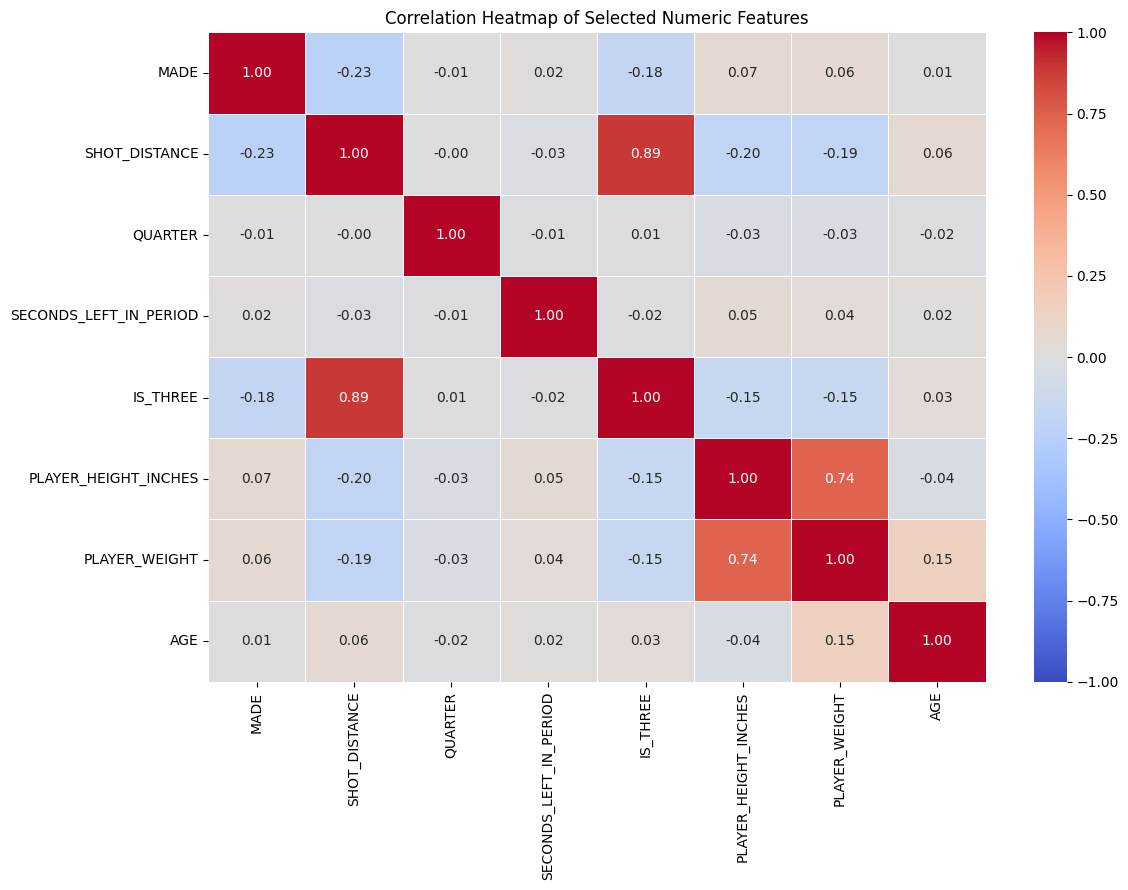

In [60]:
plt.figure(figsize=(12,9))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Heatmap of Selected Numeric Features")
plt.tight_layout()
plt.show()

Shot location is represented by the signed LOC_X and LOC_Y coordinates, but their relationship with shot outcome is spatial and nonlinear. A standard Pearson correlation may therefore underestimate the importance of location. For example, negative and positive LOC_X value represent opposite sides of the court, even when they are equally distant from the basekt. This issus should be addressed later using court heat maps, shot zones, distance, or nonlinear spatial features.

In [61]:
development_train = new_train[new_train["SEASON"] != "2024-25"].copy()
validation = new_train[new_train["SEASON"] == "2024-25"].copy()

print("Development training shape:",development_train.shape)
print("Validation shape:",validation.shape)
print(development_train["SEASON"].value_counts().sort_index())
print(validation["SEASON"].value_counts())

y_train = development_train["MADE"].copy()
y_validation = validation["MADE"].copy()

print("y_train shape: ", y_train.shape)
print("y_validation shape: ", y_validation.shape)

made_count = (y_train == 1).sum()
missed_count = (y_train == 0).sum()
print("Made shot: ", made_count)
print("Miss shot: ", missed_count)
# so we use missed as the baseline


Development training shape: (652642, 30)
Validation shape: (219527, 30)
SEASON
2021-22    216722
2022-23    217220
2023-24    218700
Name: count, dtype: int64
SEASON
2024-25    219527
Name: count, dtype: int64
y_train shape:  (652642,)
y_validation shape:  (219527,)
Made shot:  306929
Miss shot:  345713


In [62]:
# Baseline A always miss
from sklearn.metrics import(accuracy_score, roc_auc_score)

always_miss_train_predictions = np.zeros(len(y_train), dtype=int)
always_miss_validation_predictions = np.zeros(len(y_validation), dtype=int)

always_miss_train_accuracy = accuracy_score(y_train, always_miss_train_predictions)
always_miss_train_error = 1-always_miss_train_accuracy
always_miss_train_auc = roc_auc_score(y_train, always_miss_train_predictions)

always_miss_validation_accuracy = accuracy_score(y_validation, always_miss_validation_predictions)
always_miss_validation_error = 1-always_miss_validation_accuracy
always_miss_validation_auc = roc_auc_score(y_validation, always_miss_validation_predictions)

print("Always-miss training results")
print("Accuracy:", always_miss_train_accuracy)
print("Error rate:", always_miss_train_error)
print("ROC-AUC:", always_miss_train_auc)

print("\nAlways-miss validation results")
print("Accuracy:", always_miss_validation_accuracy)
print("Error rate:", always_miss_validation_error)
print("ROC-AUC:", always_miss_validation_auc)

Always-miss training results
Accuracy: 0.5297130739364001
Error rate: 0.4702869260635999
ROC-AUC: 0.5

Always-miss validation results
Accuracy: 0.5327863998505878
Error rate: 0.46721360014941216
ROC-AUC: 0.5


In [63]:
# Baseline B with distance
from sklearn.linear_model import LogisticRegression

X_train_distance = development_train[["SHOT_DISTANCE"]]
X_validation_distance = validation[["SHOT_DISTANCE"]]
y_train = development_train["MADE"]
y_validation = validation["MADE"]
print(X_train_distance.shape)
print(X_validation_distance.shape)

distance_model = LogisticRegression(max_iter=1000)
distance_model.fit(X_train_distance, y_train)

print("This is Distance-only model trained")
print("Coefficient: ", distance_model.coef_[0][0])
print("Intercept: ", distance_model.intercept_[0])


(652642, 1)
(219527, 1)
This is Distance-only model trained
Coefficient:  -0.04568654427354254
Intercept:  0.49431594340069696


In [64]:
train_distance_probability = distance_model.predict_proba(X_train_distance)[:,1]
validation_distance_probability = distance_model.predict_proba(X_validation_distance)[:,1]

train_distance_predictions = distance_model.predict(X_train_distance)
validation_distance_predictions = distance_model.predict(X_validation_distance)
distance_train_accuracy = accuracy_score(y_train, train_distance_predictions)
distance_validation_accuracy = accuracy_score(y_validation, validation_distance_predictions)

distance_train_error = 1 - distance_train_accuracy
distance_validation_error = 1 - distance_validation_accuracy

distance_train_auc = roc_auc_score(y_train, train_distance_probability)
distance_validation_auc = roc_auc_score(y_validation, validation_distance_probability)

print("Distance-only training results")
# print("Binary: ", train_distance_predictions)
print("Accuracy:", distance_train_accuracy)
print("Error rate:", distance_train_error)
print("ROC-AUC:", distance_train_auc)

print("\nDistance-only validation results")
# print("Binary: ", validation_distance_predictions)
print("Accuracy:", distance_validation_accuracy)
print("Error rate:", distance_validation_error)
print("ROC-AUC:", distance_validation_auc)

# Accuracy = (TP + TN) / total

Distance-only training results
Accuracy: 0.601652973605744
Error rate: 0.398347026394256
ROC-AUC: 0.6432395397172482

Distance-only validation results
Accuracy: 0.6029508898677611
Error rate: 0.39704911013223887
ROC-AUC: 0.6419306061944222


In [65]:
# Baseline C with multiple feature
version1_features = ["SHOT_DISTANCE", "QUARTER", "IS_THREE", "SECONDS_LEFT_IN_PERIOD", "PLAYER_HEIGHT_INCHES", "AGE", "PLAYER_WEIGHT"]
X_train_v1 = development_train[version1_features].copy()
X_validation_v1 = validation[version1_features].copy()
print("Training shape: ", X_train_v1.shape)
print("Validation shape: ", X_validation_v1.shape)


Training shape:  (652642, 7)
Validation shape:  (219527, 7)


In [66]:
version1_model = LogisticRegression(max_iter=1000)
version1_model.fit(X_train_v1, y_train)
train_v1_probability = version1_model.predict_proba(X_train_v1)[:,1]
validation_v1_probability = version1_model.predict_proba(X_validation_v1)[:,1]
# [0] is miss, [1] is made

train_v1_predictions = (train_v1_probability >= 0.5).astype(int)
validation_v1_predictions = (validation_v1_probability >= 0.5).astype(int)

v1_train_accuracy = accuracy_score(y_train, train_v1_predictions)
v1_validation_accuracy = accuracy_score(y_validation, validation_v1_predictions)
v1_train_error = 1 - v1_train_accuracy
v1_validation_error = 1 - v1_validation_accuracy
v1_train_auc = roc_auc_score(y_train, train_v1_probability)
v1_validation_auc = roc_auc_score(y_validation, validation_v1_probability)

print("Version 1 training results")
print("Accuracy:", v1_train_accuracy)
print("Error rate:", v1_train_error)
print("ROC-AUC:", v1_train_auc)

print("\nVersion 1 validation results")
print("Accuracy:", v1_validation_accuracy)
print("Error rate:", v1_validation_error)
print("ROC-AUC:", v1_validation_auc)

Version 1 training results
Accuracy: 0.6067997462621162
Error rate: 0.3932002537378838
ROC-AUC: 0.6407087328637531

Version 1 validation results
Accuracy: 0.6075516906804175
Error rate: 0.3924483093195825
ROC-AUC: 0.6406002227538317


In [67]:
model_comparison = pd.DataFrame({"Model": [
        "Always Miss (0 features)",
        "Distance Logistic Regression (1 feature)",
        "Multi-feature Logistic Regression (7 feature)"
    ],

    "Training Accuracy": [
        always_miss_train_accuracy,
        distance_train_accuracy,
        v1_train_accuracy
    ],

    "Validation Accuracy": [
        always_miss_validation_accuracy,
        distance_validation_accuracy,
        v1_validation_accuracy
    ],

    "Training Error Rate": [
        always_miss_train_error,
        distance_train_error,
        v1_train_error
    ],

    "Validation Error Rate": [
        always_miss_validation_error,
        distance_validation_error,
        v1_validation_error
    ],

    "Training ROC-AUC": [
        always_miss_train_auc,
        distance_train_auc,
        v1_train_auc
    ],

    "Validation ROC-AUC": [
        always_miss_validation_auc,
        distance_validation_auc,
        v1_validation_auc
    ]
})

model_comparison.round(4)

,Model,Training Accuracy,Validation Accuracy,Training Error Rate,Validation Error Rate,Training ROC-AUC,Validation ROC-AUC
0,Always Miss (0 features),0.5297,0.5328,0.4703,0.4672,0.5000,0.5000
1,Distance Logistic Regression (1 feature),0.6017,0.6030,0.3983,0.3970,0.6432,0.6419
2,Multi-feature Logistic Regression (7 feature),0.6068,0.6076,0.3932,0.3924,0.6407,0.6406


In [68]:
output_path = "nba_project_data/processed/train_cleaned_for_modeling.csv"
new_train.to_csv(output_path, index=False)
print("Cleaned dataset save to: ", output_path)
print("Saved shape: ", new_train.shape)
new_train.columns

Cleaned dataset save to:  nba_project_data/processed/train_cleaned_for_modeling.csv
Saved shape:  (872169, 30)


Index(['TEAM_ID', 'TEAM_NAME', 'PLAYER_ID', 'PLAYER_NAME', 'POSITION',
       'GAME_DATE', 'GAME_ID', 'GAME_EVENT_ID', 'HOME_TEAM', 'AWAY_TEAM',
       'ACTION_TYPE', 'BASIC_ZONE', 'ZONE_NAME', 'ZONE_RANGE', 'LOC_X',
       'LOC_Y', 'SHOT_DISTANCE', 'QUARTER', 'SEASON', 'MADE',
       'SECONDS_LEFT_IN_PERIOD', 'IS_THREE', 'PLAYER_HEIGHT_INCHES',
       'PLAYER_WEIGHT', 'AGE', 'COUNTRY', 'COLLEGE', 'DRAFT_YEAR',
       'DRAFT_ROUND', 'DRAFT_NUMBER'],
      dtype='object')

The multi-feature model achieved slightly higher validation accuracy than the distance-only model. However, its validation ROC-AUC was slightly lower (0.6406 versus 0.6419). Therefore, the additional variables did not improve the model's ability to rank made shots above missed shots under the current linear specification.

Remaining data issues

Several issues remain in the dataset. 

First the missing COLLEGE values were retained as a separate Unknown_or_No_College category because they may represent non-college career paths or incomplete database records. The draft variables were excluded from the initial baseline because they contain substantial missing values and are not directly related to the immediate context of a shot.

Second, three records contain 12 minutes remaining in a period. These records could not be confirmed as errors and represent a very small proportion of the dataset.

Third, several variables contain redundant information. In particular, "SHOT_MADE" and "EVENT_TYPE" directly reveal the target and must not be used as predictors. Other redundant variables, including alternative season, time, height, position, and shot-type representations, were also removed.

Fourth, some location variables have nonlinear relationships with shot outcome. Pearson correlation may not fully capture the predictive value of "LOC_X" and "LOC_Y". Shot zones, distance, spatial visualizations, or nonlinear features may be more appropriate in later models.

Finally, GAME_ID and GAME_EVENT_ID were retained for record identification and play-by-play integration, but they were not used as predictors in the baseline models.

In [69]:
new_train.head(10)

,TEAM_ID,TEAM_NAME,PLAYER_ID,PLAYER_NAME,POSITION,GAME_DATE,GAME_ID,GAME_EVENT_ID,HOME_TEAM,AWAY_TEAM,...,SECONDS_LEFT_IN_PERIOD,IS_THREE,PLAYER_HEIGHT_INCHES,PLAYER_WEIGHT,AGE,COUNTRY,COLLEGE,DRAFT_YEAR,DRAFT_ROUND,DRAFT_NUMBER
0,1610612737,Atlanta Hawks,1628381,John Collins,F-C,10-21-2021,22100014,9,ATL,DAL,...,677,0,81.0,226.0,24.0,USA,Wake Forest,2017.0,1.0,19.0
1,1610612737,Atlanta Hawks,1629631,De'Andre Hunter,F-G,10-21-2021,22100014,15,ATL,DAL,...,648,0,80.0,221.0,24.0,USA,Virginia,2019.0,1.0,4.0
2,1610612737,Atlanta Hawks,1629027,Trae Young,G,10-21-2021,22100014,28,ATL,DAL,...,566,0,73.0,164.0,23.0,USA,Oklahoma,2018.0,1.0,5.0
3,1610612737,Atlanta Hawks,1628381,John Collins,F-C,10-21-2021,22100014,37,ATL,DAL,...,526,0,81.0,226.0,24.0,USA,Wake Forest,2017.0,1.0,19.0
4,1610612737,Atlanta Hawks,203992,Bogdan Bogdanović,G,10-21-2021,22100014,42,ATL,DAL,...,494,1,78.0,225.0,29.0,Serbia,Unknown_or_No_College,2014.0,1.0,27.0
5,1610612737,Atlanta Hawks,203992,Bogdan Bogdanović,G,10-21-2021,22100014,47,ATL,DAL,...,467,1,78.0,225.0,29.0,Serbia,Unknown_or_No_College,2014.0,1.0,27.0
6,1610612737,Atlanta Hawks,1629027,Trae Young,G,10-21-2021,22100014,51,ATL,DAL,...,439,0,73.0,164.0,23.0,USA,Oklahoma,2018.0,1.0,5.0
7,1610612737,Atlanta Hawks,203991,Clint Capela,C,10-21-2021,22100014,53,ATL,DAL,...,437,0,82.0,256.0,28.0,Switzerland,Unknown_or_No_College,2014.0,1.0,25.0
8,1610612737,Atlanta Hawks,1629027,Trae Young,G,10-21-2021,22100014,59,ATL,DAL,...,400,1,73.0,164.0,23.0,USA,Oklahoma,2018.0,1.0,5.0
9,1610612737,Atlanta Hawks,1629631,De'Andre Hunter,F-G,10-21-2021,22100014,64,ATL,DAL,...,384,0,80.0,221.0,24.0,USA,Virginia,2019.0,1.0,4.0
